# Task 3 — Genetic Variation Analysis of FEV CRISPR Guides

**Executed, reproducible analysis | GRCh38 | 1000 Genomes sampled chromosomes 1 and 2**

This notebook extends the supplied Task 2 FEV guide selection (`285forw`, `259forw`, `165forw`). It evaluates (1) intersections of sampled variants with the three intended FEV targets on chromosome 2, (2) variants in reported candidate off-target sites where chromosome 1 or 2 VCF data are available, and (3) *descriptive* allele and genotype information for overlaps. It outputs auditable CSV/TSV tables and figures under `results/`.

**Scope and caution:** Supplied VCFs are sampled/sparse, not exhaustive whole-genome variant callsets. Absence of an overlapping record does **not** establish that the locus is invariant. Off-target records on other chromosomes are explicitly **not evaluated**. CRISPOR targeting scores are retained from Task 2; variant-dependent activity/off-target risk is not experimentally validated or recalculated. Genomic coordinate convention in CRISPOR tables is interpreted as **1-based inclusive** (`end-start+1 = 23`), matching the 20-nt protospacer + 3-nt PAM; this must be verified against the original CRISPOR export if differently specified.

In [1]:
from pathlib import Path
import csv, io, re, zipfile, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
INPUT = ROOT / 'input'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
print('Working directory:', ROOT)
print('Input archives:', [(p.name, round(p.stat().st_size/1e6,2)) for p in INPUT.glob('sampled_chr*.vcf.zip')])

Working directory: /mnt/data/Genetic_Variation_Analysis
Input archives: [('sampled_chr1.vcf.zip', 13.8), ('sampled_chr2.vcf.zip', 15.0)]


In [2]:
guides = pd.read_csv(INPUT/'task2'/'FEV_selected_guides.csv')
off = pd.read_csv(INPUT/'task2'/'FEV_offtargets_selected_guides.csv')
guides['chrom_normalized'] = guides['chrom'].astype(str).replace({'NC_000002.12':'2','chr2':'2'})
off['chrom_normalized'] = off['chrom'].astype(str).str.replace('chr','',regex=False)
assert len(guides)==3
assert (guides['target_end']-guides['target_start']+1==23).all(), 'Unexpected guide target lengths'
assert (off['end']-off['start']+1==23).all(), 'Unexpected off-target lengths'
assert guides['chrom_normalized'].eq('2').all()
display(guides[['guideId','chrom','target_start','target_end','protospacer','pam','genome_strand','mit_spec','cfd_spec']])
print('Candidate off-target sites:',len(off),'| on chr1/chr2:',int(off.chrom_normalized.isin(['1','2']).sum()))

,guideId,chrom,target_start,target_end,protospacer,pam,genome_strand,mit_spec,cfd_spec
0,285forw,NC_000002.12,218985396,218985418,GTTGGAGACTTTATTGCGAT,GGG,-,93,93
1,259forw,NC_000002.12,218985422,218985444,GGGTGCGCTTGGCTGTGGCG,CGG,-,72,80
2,165forw,NC_000002.12,218985516,218985538,GCGGAAAAGACACGCGCTCT,AGG,-,94,97


Candidate off-target sites: 22 | on chr1/chr2: 4


## Interval intersection and variant parsing

For a VCF record at `POS` with reference allele `REF`, its reference footprint is `[POS, POS+len(REF)-1]` (inclusive); this allows an indel to overlap a target even when the POS is just outside it. The search also includes a three-base upstream margin for potential overlapping deletion REF spans; the parser performs a full sequential scan of the supplied sampled files, so there is no assumption about maximum indel size. INFO allele frequencies may describe a broader source population than the seven displayed genotyped samples and are reported separately.

In [3]:
sites=[]
for r in guides.itertuples(index=False):
    sites.append(dict(site_type='on_target',site_id=f'FEV_{r.guideId}',guideId=r.guideId,chrom='2',start=int(r.target_start),end=int(r.target_end),strand=r.genome_strand,guide_seq=r.protospacer+r.pam,baseline_mismatch_count=0,baseline_cfd_offtarget_score=np.nan,locus_desc='FEV intended target'))
for ix,r in enumerate(off.itertuples(index=False),1):
    sites.append(dict(site_type='off_target',site_id=f'OT_{ix:02d}_{r.guideId}',guideId=r.guideId,chrom=str(r.chrom_normalized),start=int(r.start),end=int(r.end),strand=str(r.strand),guide_seq=str(r.guideSeq),baseline_mismatch_count=int(r.mismatchCount),baseline_cfd_offtarget_score=float(r.cfdOfftargetScore),locus_desc=str(r.locusDesc)))
sites_df=pd.DataFrame(sites)
sites_df['coverage_status']=np.where(sites_df.chrom.isin(['1','2']),'screened_in_supplied_sampled_vcf','chromosome_not_supplied')
sites_df.to_csv(OUT/'evaluated_sites.csv',index=False)
display(sites_df.groupby(['site_type','coverage_status']).size().rename('sites').reset_index())

,site_type,coverage_status,sites
0,off_target,chromosome_not_supplied,18
1,off_target,screened_in_supplied_sampled_vcf,4
2,on_target,screened_in_supplied_sampled_vcf,3


In [4]:
target_intervals={chrom:[] for chrom in ['1','2']}
for site in sites:
    if site['chrom'] in target_intervals:
        target_intervals[site['chrom']].append(site)
def info_as_dict(info):
    d={}
    for item in info.split(';'):
        if '=' in item:
            k,v=item.split('=',1);d[k]=v
        else: d[item]=True
    return d
def number_or_nan(s):
    try:return float(s.split(',')[0])
    except (ValueError,AttributeError):return np.nan
variant_rows=[]; vcf_metadata=[]
for chrom in ['1','2']:
    filepath=INPUT/f'sampled_chr{chrom}.vcf.zip'
    with zipfile.ZipFile(filepath) as zf:
        filename=next(n for n in zf.namelist() if n.endswith('.vcf'))
        with zf.open(filename) as binary:
            samples=[];count=0;hit_records=0
            for raw in io.TextIOWrapper(binary,encoding='utf-8'):
                if raw.startswith('##'):continue
                if raw.startswith('#CHROM'):
                    samples=raw.rstrip('\n').split('\t')[9:];continue
                if not raw.strip(): continue
                count+=1
                f=raw.rstrip('\n').split('\t')
                if len(f)<8: continue
                pos=int(f[1]); ref=f[3]; alt=f[4];end=pos+len(ref)-1
                matching=[s for s in target_intervals[chrom] if pos<=s['end'] and end>=s['start']]
                if not matching:continue
                hit_records+=1; info=info_as_dict(f[7]); genos=f[9:]
                called=[g.split(':')[0] for g in genos]
                carriers=sum(any(a not in ('.','0') for a in re.split(r'[|/]',g)) for g in called)
                for s in matching:
                    base=dict(site_id=s['site_id'],site_type=s['site_type'],guideId=s['guideId'],chrom=chrom,site_start=s['start'],site_end=s['end'],variant_pos=pos,variant_end=end,variant_id=f[2],ref=ref,alt=alt,filter=f[6],variant_type='SNV' if len(ref)==1 and all(len(a)==1 for a in alt.split(',')) else 'INDEL_or_complex',overlap_bases=min(end,s['end'])-max(pos,s['start'])+1,position_in_target_1based=max(pos,s['start'])-s['start']+1,AF=number_or_nan(info.get('AF')),EAS_AF=number_or_nan(info.get('EAS_AF')),EUR_AF=number_or_nan(info.get('EUR_AF')),AFR_AF=number_or_nan(info.get('AFR_AF')),AMR_AF=number_or_nan(info.get('AMR_AF')),SAS_AF=number_or_nan(info.get('SAS_AF')),AC=info.get('AC',''),AN=info.get('AN',''),sampled_genotyped_individuals=len(genos),sampled_alt_carriers=carriers,sampled_carrier_fraction=carriers/len(genos) if genos else np.nan,genotypes=';'.join(f'{x}:{g}' for x,g in zip(samples,called)))
                    base['target_region']=('PAM_or_near_boundary' if base['position_in_target_1based']>=21 else 'protospacer_or_near_boundary')
                    variant_rows.append(base)
    vcf_metadata.append(dict(chrom=chrom,records_scanned=count,records_intersecting_any_site=hit_records,samples_in_vcf=len(samples),archive=filepath.name))
variants=pd.DataFrame(variant_rows)
if variants.empty:
    variants=pd.DataFrame(columns=['site_id','site_type','guideId','chrom','site_start','site_end','variant_pos','variant_end','variant_id','ref','alt','filter','variant_type','overlap_bases','position_in_target_1based','AF','EAS_AF','EUR_AF','AFR_AF','AMR_AF','SAS_AF','AC','AN','sampled_genotyped_individuals','sampled_alt_carriers','sampled_carrier_fraction','genotypes','target_region'])
variants.to_csv(OUT/'variant_site_overlaps.csv',index=False)
scan=pd.DataFrame(vcf_metadata);scan.to_csv(OUT/'vcf_scan_summary.csv',index=False)
display(scan)
print('Total site-variant overlaps:',len(variants));display(variants[['site_id','guideId','chrom','variant_pos','ref','alt','AF','sampled_alt_carriers']].head(30))

,chrom,records_scanned,records_intersecting_any_site,samples_in_vcf,archive
0,1,691946,0,7,sampled_chr1.vcf.zip
1,2,749030,1,7,sampled_chr2.vcf.zip


Total site-variant overlaps: 1


,site_id,guideId,chrom,variant_pos,ref,alt,AF,sampled_alt_carriers
0,OT_08_259forw,259forw,2,86789946,C,G,0.22,4


## Results and interpretation

Observed VCF variants are intersected with each site. When there are no overlaps, this means **no intersecting records in this particular sampled VCF**, not proof of universal absence. A detected off-target variant alone does not prove that a new guide match is created or that binding is improved: that would require reference sequence reconstruction, correct strand handling, mismatch/PAM recalculation and ideally functional validation.

In [5]:
counts=variants.groupby('site_id').size().rename('overlapping_variant_records') if len(variants) else pd.Series(dtype=int,name='overlapping_variant_records')
site_summary=sites_df.merge(counts,left_on='site_id',right_index=True,how='left')
site_summary['overlapping_variant_records']=site_summary['overlapping_variant_records'].fillna(0).astype(int)
site_summary['interpretation']=np.where(site_summary.coverage_status.eq('chromosome_not_supplied'),'Not assessed: chromosome VCF not provided',np.where(site_summary.overlapping_variant_records.gt(0),'Overlapping record(s) detected in sampled VCF','No overlapping records in sampled VCF (not proof of no variation)'))
site_summary.to_csv(OUT/'site_level_variant_summary.csv',index=False)
on_target=site_summary.query("site_type=='on_target'").copy()
off_target=site_summary.query("site_type=='off_target'").copy()
on_target.to_csv(OUT/'FEV_on_target_variant_summary.csv',index=False)
off_target.to_csv(OUT/'off_target_variant_summary.csv',index=False)
display(on_target[['guideId','chrom','start','end','overlapping_variant_records','interpretation']]);display(off_target[['guideId','chrom','start','end','overlapping_variant_records','coverage_status']])

,guideId,chrom,start,end,overlapping_variant_records,interpretation
0,285forw,2,218985396,218985418,0,No overlapping records in sampled VCF (not pro...
1,259forw,2,218985422,218985444,0,No overlapping records in sampled VCF (not pro...
2,165forw,2,218985516,218985538,0,No overlapping records in sampled VCF (not pro...


,guideId,chrom,start,end,overlapping_variant_records,coverage_status
3,165forw,22,49615310,49615332,0,chromosome_not_supplied
4,165forw,8,141996346,141996368,0,chromosome_not_supplied
5,285forw,12,18866010,18866032,0,chromosome_not_supplied
6,285forw,3,178554240,178554262,0,chromosome_not_supplied
7,285forw,5,30478642,30478664,0,chromosome_not_supplied
8,259forw,7,148458090,148458112,0,chromosome_not_supplied
9,259forw,19,47413432,47413454,0,chromosome_not_supplied
10,259forw,2,86789925,86789947,1,screened_in_supplied_sampled_vcf
11,259forw,17,79791491,79791513,0,chromosome_not_supplied
12,259forw,11,120255136,120255158,0,chromosome_not_supplied


In [6]:
stats=pd.DataFrame([{'metric':'Selected FEV guides','value':len(guides)},
 {'metric':'Reported candidate off-target sites','value':len(off)},
 {'metric':'Intended targets screened (chr2)','value':int((sites_df.site_type.eq('on_target')&sites_df.coverage_status.eq('screened_in_supplied_sampled_vcf')).sum())},
 {'metric':'Off-target sites screened (chr1 and chr2)','value':int((sites_df.site_type.eq('off_target')&sites_df.coverage_status.eq('screened_in_supplied_sampled_vcf')).sum())},
 {'metric':'Off-target sites not screened (other chromosomes)','value':int((sites_df.site_type.eq('off_target')&sites_df.coverage_status.eq('chromosome_not_supplied')).sum())},
 {'metric':'Distinct sampled VCF records intersecting any site','value':int(len(variants[['chrom','variant_pos','ref','alt']].drop_duplicates())) if len(variants) else 0},
 {'metric':'Target-site x variant overlaps','value':int(len(variants))},
 {'metric':'FEV guides with sampled overlaps','value':int((on_target.overlapping_variant_records>0).sum())},
 {'metric':'Candidate off-target sites with sampled overlaps','value':int((off_target.overlapping_variant_records>0).sum())}])
stats.to_csv(OUT/'analysis_metrics.csv',index=False);display(stats)

,metric,value
0,Selected FEV guides,3
1,Reported candidate off-target sites,22
2,Intended targets screened (chr2),3
3,Off-target sites screened (chr1 and chr2),4
4,Off-target sites not screened (other chromosomes),18
5,Distinct sampled VCF records intersecting any ...,1
6,Target-site x variant overlaps,1
7,FEV guides with sampled overlaps,0
8,Candidate off-target sites with sampled overlaps,1


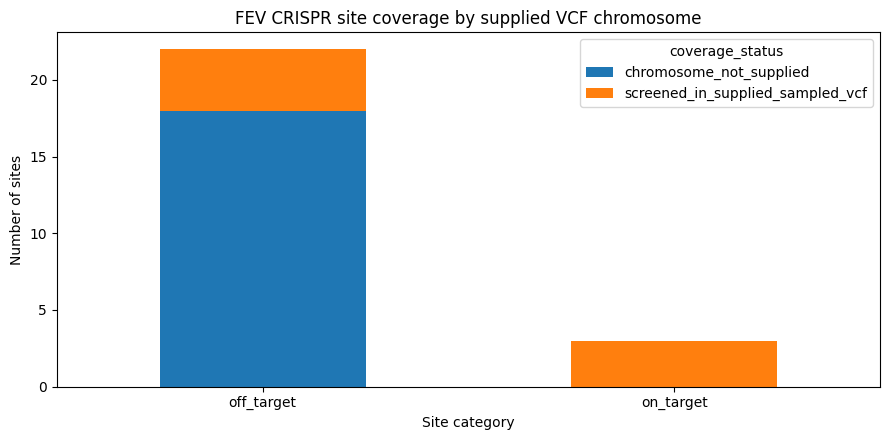

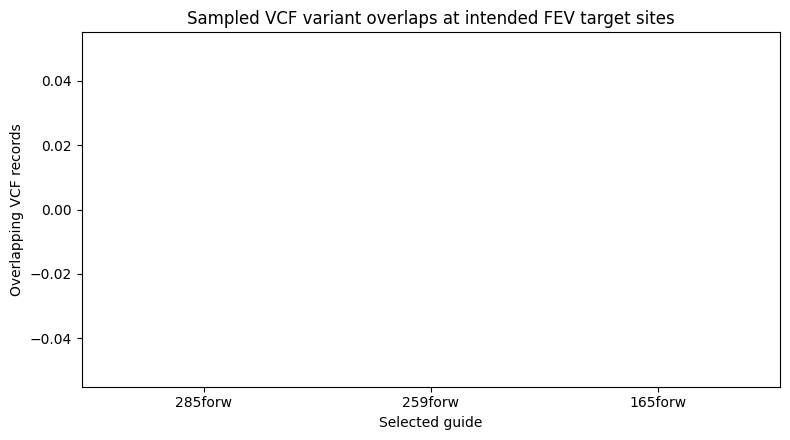

In [7]:
fig,ax=plt.subplots(figsize=(9,4.5))
plot=site_summary.groupby(['site_type','coverage_status']).size().unstack(fill_value=0)
plot.plot(kind='bar',stacked=True,ax=ax)
ax.set(title='FEV CRISPR site coverage by supplied VCF chromosome',xlabel='Site category',ylabel='Number of sites')
ax.tick_params(axis='x',rotation=0)
fig.tight_layout();fig.savefig(OUT/'site_coverage.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(8,4.5))
ax.bar(on_target['guideId'],on_target['overlapping_variant_records'])
ax.set(title='Sampled VCF variant overlaps at intended FEV target sites',xlabel='Selected guide',ylabel='Overlapping VCF records')
ax.yaxis.get_major_locator().set_params(integer=True)
fig.tight_layout();fig.savefig(OUT/'on_target_overlaps.png',dpi=180);plt.show()

In [8]:
notes=f"""# Task 3 results summary (generated from executed notebook)

- Selected FEV guides: {len(guides)} (285forw, 259forw, 165forw), all on chr2 (GRCh38).
- Candidate off-target sites supplied by Task 2: {len(off)}.
- Candidate off-target sites screened using the provided chr1/chr2 sampled VCFs: {int((off_target.coverage_status=='screened_in_supplied_sampled_vcf').sum())}.
- Candidate off-target sites NOT evaluated because corresponding chromosome VCF was not supplied: {int((off_target.coverage_status=='chromosome_not_supplied').sum())}.
- Overlapping sampled VCF records on intended FEV guide sites: {int(variants.site_type.eq('on_target').sum())}.
- Overlapping sampled VCF records on screenable candidate off-target sites: {int(variants.site_type.eq('off_target').sum())}.
- VCF scan records, chr1: {int(scan.loc[scan.chrom=='1','records_scanned'].iloc[0])}; chr2: {int(scan.loc[scan.chrom=='2','records_scanned'].iloc[0])}.

## Limitations
Only supplied sampled variant records were analysed, and chromosome 3 onwards were not available (except chromosome 1 and 2). No overlap does not imply absence of a polymorphism. Variant site intersections cannot by themselves establish altered CRISPR binding or modified off-target specificity. Coordinate convention is assumed 1-based inclusive and should be confirmed against the originating CRISPOR output. AF reflects supplied metadata rather than the seven genotypes alone. Results are computational and require experimental validation.

## Reproducibility
Run this notebook from the folder containing `input/task2/FEV_selected_guides.csv`, `input/task2/FEV_offtargets_selected_guides.csv`, and the two `input/sampled_chr*.vcf.zip` archives. All results are regenerated under `results/`.
"""
(OUT/'RESULTS_README.md').write_text(notes,encoding='utf-8')
print(notes)

# Task 3 results summary (generated from executed notebook)

- Selected FEV guides: 3 (285forw, 259forw, 165forw), all on chr2 (GRCh38).
- Candidate off-target sites supplied by Task 2: 22.
- Candidate off-target sites screened using the provided chr1/chr2 sampled VCFs: 4.
- Candidate off-target sites NOT evaluated because corresponding chromosome VCF was not supplied: 18.
- Overlapping sampled VCF records on intended FEV guide sites: 0.
- Overlapping sampled VCF records on screenable candidate off-target sites: 1.
- VCF scan records, chr1: 691946; chr2: 749030.

## Limitations
Only supplied sampled variant records were analysed, and chromosome 3 onwards were not available (except chromosome 1 and 2). No overlap does not imply absence of a polymorphism. Variant site intersections cannot by themselves establish altered CRISPR binding or modified off-target specificity. Coordinate convention is assumed 1-based inclusive and should be confirmed against the originating CRISPOR output. AF r